### Code for making figure 4 and table 1 in Nilssen et al 2026

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
from scipy.stats import ttest_ind
import seaborn as sns
from matplotlib.lines import Line2D

In [2]:
mbs_accum = pd.read_csv("data/mbs_accum_record.csv")

In [3]:
# Change points (each year marks the START of the next regime)
change_points = [873, 1127, 1322, 1461, 1509, 1595, 1651, 1754, 1880]

# Ensure sorted from oldest to newest
change_points = sorted(change_points)

# Column names
year_col = 'Year'
accum_col = 'IE_accum_apres'

last_year = mbs_accum[year_col].max()
rows = []


# Regimes between change points
for i in range(len(change_points) - 1):

    start_year = change_points[i]
    end_year = change_points[i + 1] - 1

    subset = mbs_accum[
        (mbs_accum[year_col] >= start_year) &
        (mbs_accum[year_col] <= end_year)
    ]

    rows.append({
        "regime": f"{start_year}-{end_year}",
        "start_year": start_year,
        "end_year": end_year,
        "mean": subset[accum_col].mean(),
        "std": subset[accum_col].std(),
        "n_years": len(subset)
    })

# Final regime
start_year = change_points[-1]
end_year = last_year

subset = mbs_accum[
    (mbs_accum[year_col] >= start_year) &
    (mbs_accum[year_col] <= end_year)
]

rows.append({
    "regime": f"{start_year}-{end_year}",
    "start_year": start_year,
    "end_year": end_year,
    "mean": subset[accum_col].mean(),
    "std": subset[accum_col].std(),
    "n_years": len(subset)
})

regime_stats = pd.DataFrame(rows)

print(regime_stats)

      regime  start_year  end_year      mean       std  n_years
0   873-1126         873      1126  0.298632  0.084847      254
1  1127-1321        1127      1321  0.242158  0.070644      195
2  1322-1460        1322      1460  0.298303  0.091663      139
3  1461-1508        1461      1508  0.232452  0.078548       48
4  1509-1594        1509      1594  0.275910  0.079858       86
5  1595-1650        1595      1650  0.316932  0.087388       56
6  1651-1753        1651      1753  0.273490  0.079372      103
7  1754-1879        1754      1879  0.240067  0.074750      126
8  1880-2017        1880      2017  0.290246  0.081952      138


In [4]:
# make regime column

change_points = sorted(change_points)

def assign_regime(year):
    for i in range(len(change_points) - 1):
        if change_points[i] <= year < change_points[i + 1]:
            return f"{change_points[i]}-{change_points[i+1]-1}"

    if year >= change_points[-1]:
        return f"{change_points[-1]}-{mbs_accum['Year'].max()}"

mbs_accum["regime"] = mbs_accum["Year"].apply(assign_regime)
mbs_accum

,Depth,Horizon_Type,Year,depth_corrected,layer_thickness,fitted_densities,IE_layer_thickness,IE_depth,age,IE_accum_nye_1978,IE_accum_SR2.59,IE_accum_apres,regime
0,0.588,1,2017,0.2940,0.588,443.839763,0.284600,0.141457,0,0.284620,0.284600,0.284600,1880-2017
1,1.044,1,2016,0.8160,0.456,452.858835,0.225195,0.396700,1,0.225240,0.225253,0.225253,1880-2017
2,1.717,1,2015,1.3805,0.673,462.125156,0.339161,0.678355,2,0.339277,0.339336,0.339336,1880-2017
3,2.024,1,2014,1.8705,0.307,469.783619,0.157278,0.927353,3,0.157351,0.157400,0.157400,1880-2017
4,2.444,1,2013,2.2340,0.420,475.246751,0.217670,1.114665,4,0.217793,0.217896,0.217896,1880-2017
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1140,293.732,1,877,293.5410,0.382,916.899546,0.381958,271.609468,1140,0.442755,0.513151,0.513151,873-1126
1141,294.013,1,876,293.8725,0.281,916.900567,0.280970,271.940932,1141,0.325755,0.377573,0.377573,873-1126
1142,294.319,1,875,294.1660,0.306,916.901462,0.305967,272.234400,1142,0.354798,0.411272,0.411272,873-1126
1143,294.501,1,874,294.4100,0.182,916.902200,0.181981,272.478374,1143,0.211054,0.244677,0.244677,873-1126


In [9]:

results = []

for regime in mbs_accum['regime'].unique():

    regime_data = mbs_accum.loc[
        mbs_accum['regime'] == regime,
        'IE_accum_apres'
    ]

    rest_data = mbs_accum.loc[
        mbs_accum['regime'] != regime,
        'IE_accum_apres'
    ]

    t_stat, p_value = ttest_ind(
        regime_data,
        rest_data,
        equal_var=False # welch's t-test
    )

    results.append({
        'regime': regime,
        'regime_mean': regime_data.mean(),
        'rest_mean': rest_data.mean(),
        'mean_difference': regime_data.mean() - rest_data.mean(),
        'p_value': p_value
    })

results_df = pd.DataFrame(results)

print(results_df)

      regime  regime_mean  rest_mean  mean_difference       p_value
0  1880-2017     0.290246   0.273674         0.016572  2.788357e-02
1  1754-1879     0.240067   0.280074        -0.040006  9.627273e-08
2  1651-1753     0.273490   0.275887        -0.002397  7.720738e-01
3  1595-1650     0.316932   0.273549         0.043382  5.869437e-04
4  1509-1594     0.275910   0.275652         0.000259  9.771453e-01
5  1461-1508     0.232452   0.277562        -0.045110  2.950212e-04
6  1322-1460     0.298303   0.272544         0.025759  2.004175e-03
7  1127-1321     0.242158   0.282550        -0.040393  1.570143e-11
8   873-1126     0.298632   0.269126         0.029506  1.381975e-06


In [10]:
change_points = sorted(change_points)

year_col = "Year"
acc_col = "IE_accum_apres"

rows = []

for i in range(1, len(change_points)):

    cp = change_points[i]

    # Regime before change point
    before_start = change_points[i-1]
    before_end = cp - 1

    before = mbs_accum.loc[
        (mbs_accum[year_col] >= before_start) &
        (mbs_accum[year_col] <= before_end),
        acc_col
    ].dropna()

    # Regime after change point
    if i < len(change_points) - 1:
        after_start = cp
        after_end = change_points[i+1] - 1
    else:
        after_start = cp
        after_end = mbs_accum[year_col].max()

    after = mbs_accum.loc[
        (mbs_accum[year_col] >= after_start) &
        (mbs_accum[year_col] <= after_end),
        acc_col
    ].dropna()

    mean_before = before.mean()
    mean_after = after.mean()

    tstat, pval = ttest_ind(
        before,
        after,
        equal_var=False,  # Welch t-test
        nan_policy="omit"
    )

    rows.append({
        "Change Point": cp,
        "RSI": np.nan,  # fill manually later
        "Mean Before": mean_before,
        "Mean After": mean_after,
        "Absolute Change": mean_after - mean_before,
        "% Change": 100 * (mean_after - mean_before) / mean_before,
        "p-value": pval
    })

change_point_table = pd.DataFrame(rows)

change_point_table = change_point_table.round({
    "Mean Before": 3,
    "Mean After": 3,
    "Absolute Change": 3,
    "% Change": 1,
    "p-value": 4
})

change_point_table

,Change Point,RSI,Mean Before,Mean After,Absolute Change,% Change,p-value
0,1127,NaN,0.299,0.242,-0.056,-18.9,0.0000
1,1322,NaN,0.242,0.298,0.056,23.2,0.0000
2,1461,NaN,0.298,0.232,-0.066,-22.1,0.0000
3,1509,NaN,0.232,0.276,0.043,18.7,0.0029
4,1595,NaN,0.276,0.317,0.041,14.9,0.0056
5,1651,NaN,0.317,0.273,-0.043,-13.7,0.0026
6,1754,NaN,0.273,0.240,-0.033,-12.2,0.0013
7,1880,NaN,0.240,0.290,0.050,20.9,0.0000


In [11]:
# make column that classifies each year by regime and whether it is low, high, or average

# Long-term mean
long_term_mean = mbs_accum['IE_accum_apres'].mean()

# Mean accumulation for each regime
regime_means = mbs_accum.groupby('regime')['IE_accum_apres'].mean()

# Map regime means back onto every row
mbs_accum['regime_mean'] = mbs_accum['regime'].map(regime_means)


# 5% tolerance
tol = 0.05 * long_term_mean

mbs_accum['regime_category'] = np.select(
    [
        mbs_accum['regime_mean'] > long_term_mean + tol,
        mbs_accum['regime_mean'] < long_term_mean - tol
    ],
    [
        'high',
        'low'
    ],
    default='average'
)

mbs_accum

,Depth,Horizon_Type,Year,depth_corrected,layer_thickness,fitted_densities,IE_layer_thickness,IE_depth,age,IE_accum_nye_1978,IE_accum_SR2.59,IE_accum_apres,regime,regime_mean,regime_category
0,0.588,1,2017,0.2940,0.588,443.839763,0.284600,0.141457,0,0.284620,0.284600,0.284600,1880-2017,0.290246,high
1,1.044,1,2016,0.8160,0.456,452.858835,0.225195,0.396700,1,0.225240,0.225253,0.225253,1880-2017,0.290246,high
2,1.717,1,2015,1.3805,0.673,462.125156,0.339161,0.678355,2,0.339277,0.339336,0.339336,1880-2017,0.290246,high
3,2.024,1,2014,1.8705,0.307,469.783619,0.157278,0.927353,3,0.157351,0.157400,0.157400,1880-2017,0.290246,high
4,2.444,1,2013,2.2340,0.420,475.246751,0.217670,1.114665,4,0.217793,0.217896,0.217896,1880-2017,0.290246,high
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1140,293.732,1,877,293.5410,0.382,916.899546,0.381958,271.609468,1140,0.442755,0.513151,0.513151,873-1126,0.298632,high
1141,294.013,1,876,293.8725,0.281,916.900567,0.280970,271.940932,1141,0.325755,0.377573,0.377573,873-1126,0.298632,high
1142,294.319,1,875,294.1660,0.306,916.901462,0.305967,272.234400,1142,0.354798,0.411272,0.411272,873-1126,0.298632,high
1143,294.501,1,874,294.4100,0.182,916.902200,0.181981,272.478374,1143,0.211054,0.244677,0.244677,873-1126,0.298632,high


In [14]:

# =============================================================================
# Sort regimes chronologically
# =============================================================================

regimes = (
    mbs_accum[['regime', 'regime_category']]
    .drop_duplicates()
    .copy()
)

regimes['start_year'] = (
    regimes['regime']
    .str.split('-')
    .str[0]
    .astype(int)
)

regimes = regimes.sort_values('start_year')

# =============================================================================
# Colours
# =============================================================================

high_colour = "#01665E"
low_colour = "#8C510A"

colour_map = {
    'high': high_colour,      # teal
    'low': low_colour,       # brown
    'average': '#000000'    # black
}

# Long-term mean
full_mean = mbs_accum['IE_accum_apres'].mean()

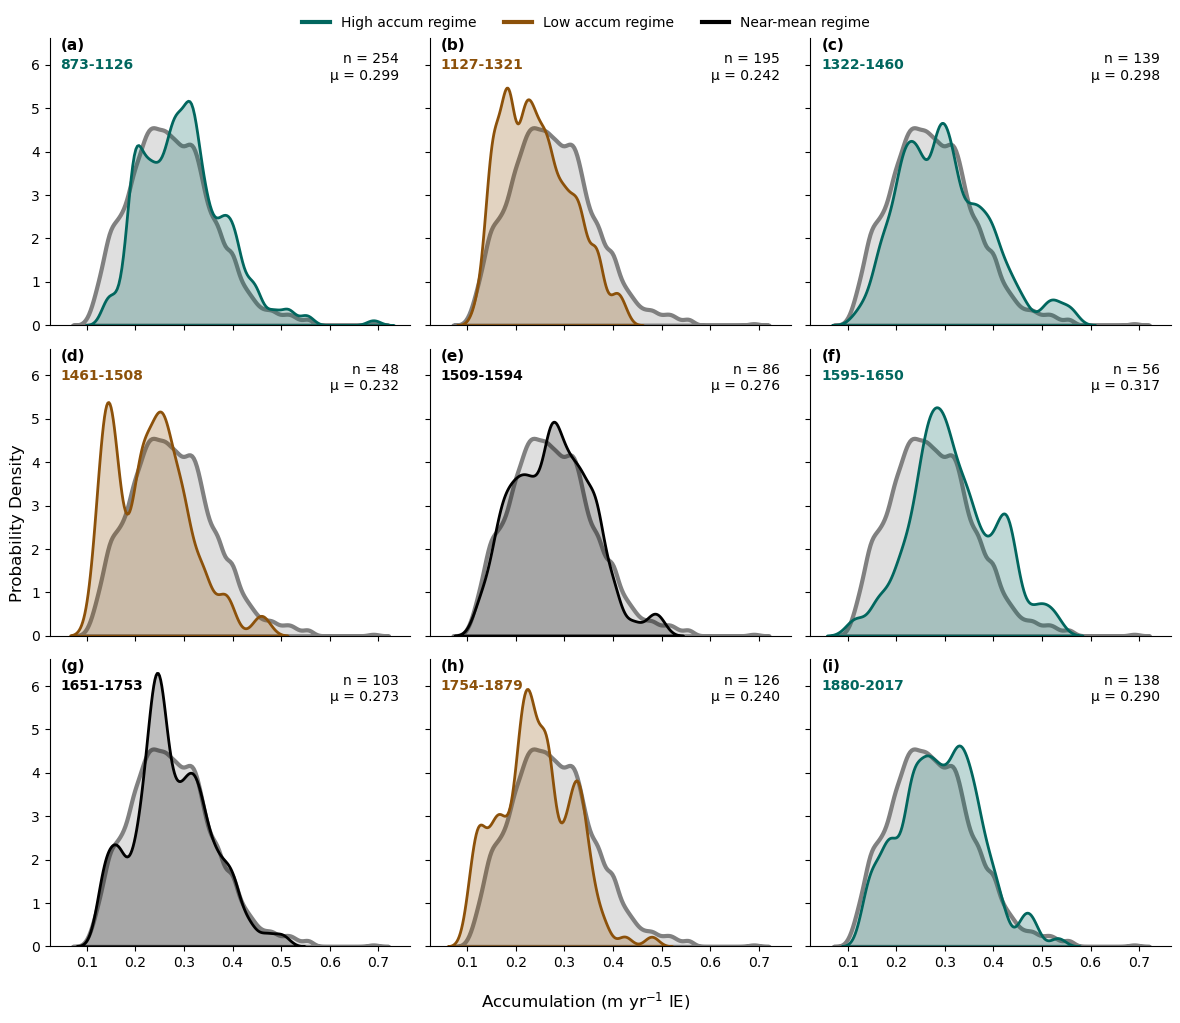

In [18]:
timestamp = datetime.now().strftime('%Y%m%d_%H%M')



# =============================================================================
# Figure
# =============================================================================

fig, axes = plt.subplots(
    3,
    3,
    figsize=(12, 10),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

# =============================================================================
# Plot each regime
# =============================================================================

bw_value = 0.5


panel_labels = ['(a)', '(b)', '(c)',
                '(d)', '(e)', '(f)',
                '(g)', '(h)', '(i)']


for ax, label, (_, row) in zip(axes, panel_labels, regimes.iterrows()):

    regime = row['regime']
    category = row['regime_category']

    subset = mbs_accum.loc[
        mbs_accum['regime'] == regime,
        'IE_accum_apres'
    ]

    regime_mean = subset.mean()

    # -------------------------------------------------------------------------
    # Full-record KDE
    # -------------------------------------------------------------------------

    sns.kdeplot(
        mbs_accum['IE_accum_apres'],
        ax=ax,
        color='0.5',
        lw=3,
        bw_adjust=bw_value,
        fill=True,
        alpha=0.25
    )


    # -------------------------------------------------------------------------
    # Regime KDE
    # -------------------------------------------------------------------------

    
    sns.kdeplot(
        subset,
        ax=ax,
        color=colour_map[category],
        fill=True,
        alpha=0.25,
        lw=2,
        bw_adjust=bw_value
    )



    # -------------------------------------------------------------------------
    # Panel labels
    # -------------------------------------------------------------------------

    
    ax.text(
        0.03,
        0.93,
        regime,
        color=colour_map[category],
        transform=ax.transAxes,
        ha='left',
        va='top',
        fontsize=10,
        fontweight='bold'
    )

    
    ax.text(
        0.03,
        1.0,
        label,
        transform=ax.transAxes,
        ha='left',
        va='top',
        fontsize=11,
        fontweight='bold'
    )



    ax.text(
        0.97,
        0.95,
        (
            f'n = {len(subset)}\n'
            f'μ = {regime_mean:.3f}'
        ),
        transform=ax.transAxes,
        ha='right',
        va='top',
        fontsize=10
    )

# =============================================================================
# Axis labels
# =============================================================================

fig.supxlabel(
    'Accumulation (m yr$^{-1}$ IE)',
    fontsize=12
)

fig.supylabel(
    'Probability Density',
    fontsize=12
)

# =============================================================================
# Legend
# =============================================================================

legend_items = [

    Line2D(
        [0], [0],
        color=high_colour,
        lw=3,
        label='High accum regime'
    ),
    Line2D(
        [0], [0],
        color=low_colour,
        lw=3,
        label='Low accum regime'
    ),
    Line2D(
        [0], [0],
        color='#000000',
        lw=3,
        label='Near-mean regime'
    )
]

fig.legend(
    handles=legend_items,
    loc='upper center',
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.5, 1.02)
)


for ax in axes:
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.label_outer()

sns.despine()

plt.tight_layout()

# plt.savefig(f"figs/pdf_panels_{timestamp}.pdf", bbox_inches='tight')